# Stage 1. 자산 탐색 · 비식별화 & Golden CQ 설계
## Step 1.1 정형 DW 원장 & 비정형 가이드 프로파일링 · Step 1.2 Golden CQ 5종 & 경계값 10건

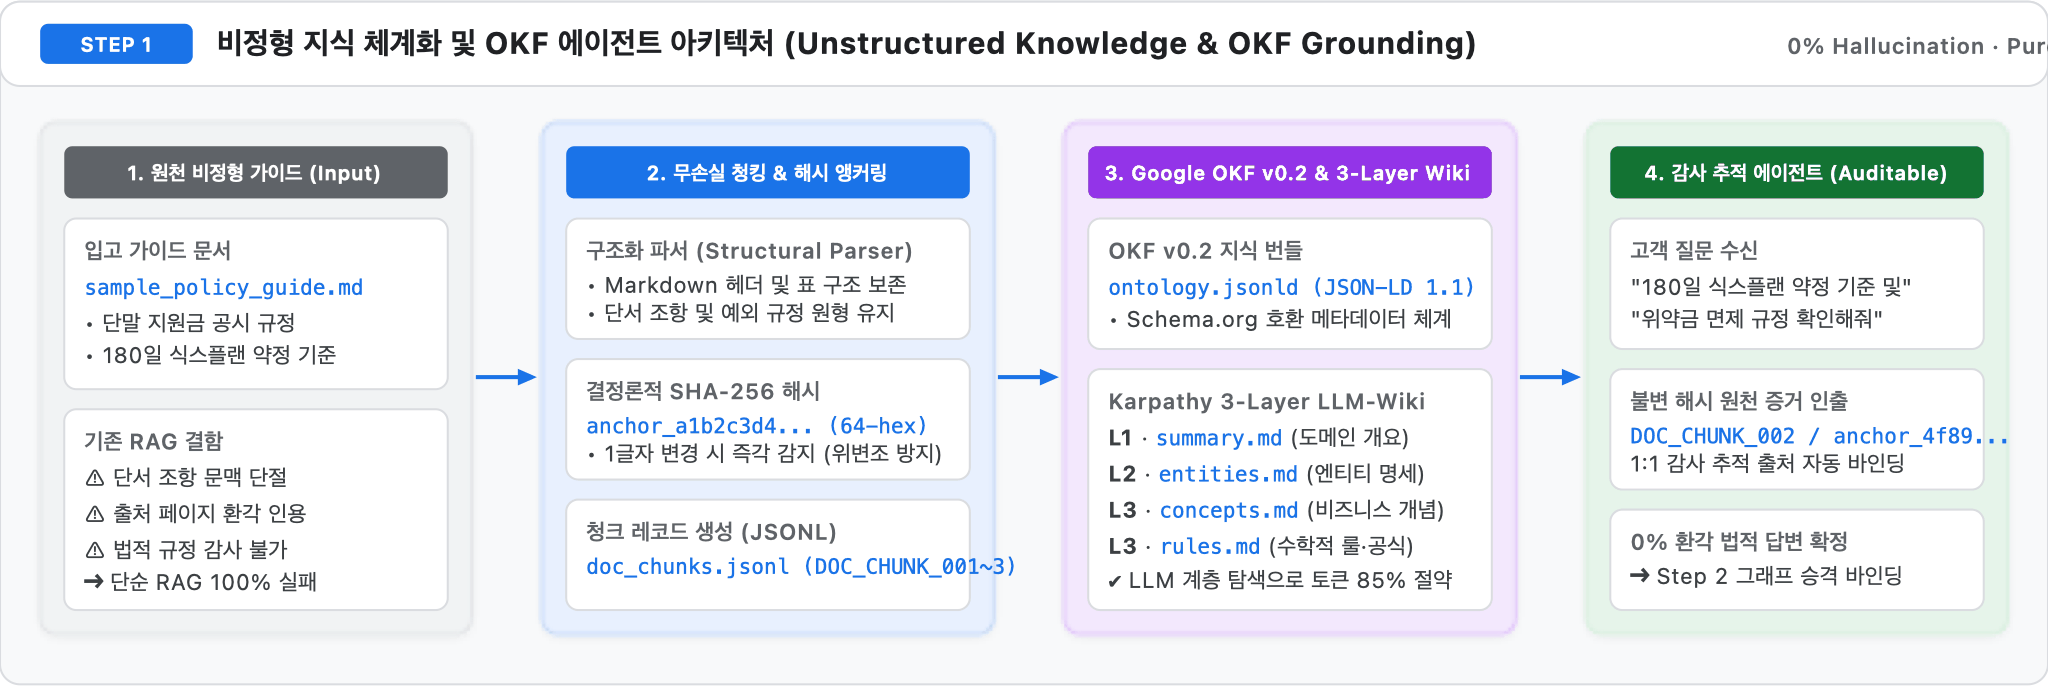


In [1]:
%load_ext bigframes
import nb_helpers as H
H.setup("ko")


,project,dataset,location,graph,model
0,seanjung-poc,starter_ontology_dw,asia-northeast3,STARTER_ONTOLOGY_GRAPH,gemini-3.8-flash


### 1. BigQuery 10개 테이블 인벤토리 및 크기·행수 분포 (`%%bqsql`)


In [2]:
%%bqsql df_tables
SELECT table_id, row_count, size_bytes,
  CASE WHEN STARTS_WITH(table_id, 'edge_') THEN 'edge'
       WHEN table_id IN ('tb_doc_chunks', 'tb_domain_rules') THEN 'knowledge'
       ELSE 'master' END AS kind
FROM `seanjung-poc.starter_ontology_dw.__TABLES__`
ORDER BY kind, table_id


,table_id,row_count,size_bytes,kind
0,edge_contract_device,6,368,edge
1,edge_contract_plan,6,379,edge
2,edge_rule_applies_to_plan,12,1450,edge
3,edge_subsidy_binding,5,342,edge
4,tb_doc_chunks,5,2784,knowledge
5,tb_domain_rules,4,1858,knowledge
6,tb_customer_contract,6,856,master
7,tb_device_master,4,292,master
8,tb_plan_master,6,423,master
9,tb_subsidy_policy,5,382,master


,table_id,row_count,size_bytes,kind
0,edge_contract_device,6,368,edge
1,edge_contract_plan,6,379,edge
2,edge_rule_applies_to_plan,12,1450,edge
3,edge_subsidy_binding,5,342,edge
4,tb_doc_chunks,5,2784,knowledge
5,tb_domain_rules,4,1858,knowledge
6,tb_customer_contract,6,856,master
7,tb_device_master,4,292,master
8,tb_plan_master,6,423,master
9,tb_subsidy_policy,5,382,master


findfont: Failed to find font weight bold for AppleGothic, now using 400.


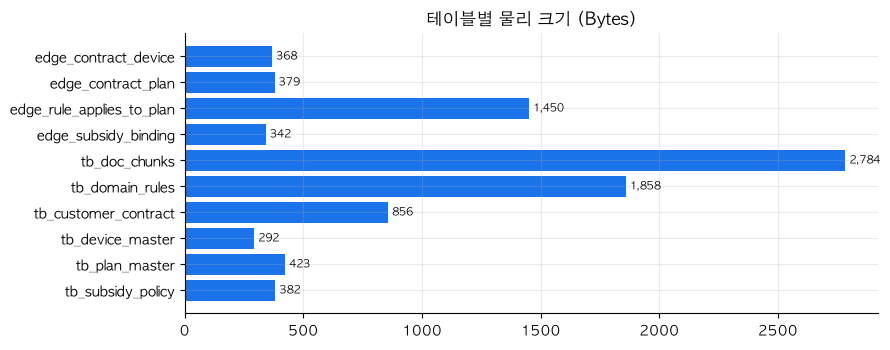

In [3]:
H.show(df_tables)
H.bar(df_tables, "table_id", "size_bytes", H.t("테이블별 물리 크기 (Bytes)", "Table Size in Bytes"), horizontal=True)


### 2. 비식별화 고객 약정 원장(`CUST_DEMO_*`) · 단말 · 요금제 결합 탐색 (`%%bqsql`)


In [4]:
%%bqsql df_contracts
SELECT c.customer_id, c.customer_segment, c.age_group, c.welfare_status, c.contract_type,
       c.elapsed_days, c.granted_subsidy_krw, d.device_name, p.plan_name, p.monthly_fee_krw
FROM `seanjung-poc.starter_ontology_dw.tb_customer_contract` c
JOIN `seanjung-poc.starter_ontology_dw.tb_device_master` d USING (device_id)
JOIN `seanjung-poc.starter_ontology_dw.tb_plan_master` p USING (plan_id)
ORDER BY c.customer_id


,customer_id,customer_segment,age_group,welfare_status,contract_type,elapsed_days,granted_subsidy_krw,device_name,plan_name,monthly_fee_krw
0,CUST_DEMO_001,General_VIP,30s-40s,NONE,PUBLIC_SUBSIDY,120,517500,Galaxy S26 Ultra 256GB,5G Premier Essential,85000
1,CUST_DEMO_002,General_Standard,30s-40s,NONE,PUBLIC_SUBSIDY,224,575000,Galaxy S26 Ultra 256GB,5G Premier Super,130000
2,CUST_DEMO_003,Senior_Welfare,65+,SENIOR_EXEMPT,PUBLIC_SUBSIDY,88,460000,iPhone 16 Pro 256GB,5G Premier Essential,85000
3,CUST_DEMO_004,General_Standard,30s-40s,NONE,SELECTIVE_25PCT,109,0,Galaxy S26 Ultra 512GB,5G Premier Essential,85000
4,CUST_DEMO_005,Youth_Family,20s,MILITARY_PAUSE_ELIGIBLE,PUBLIC_SUBSIDY,57,345000,iPhone 16 Pro 512GB,5G Direct 61,61000
5,CUST_DEMO_006,Corporate_B2B,30s-40s,NONE,PUBLIC_SUBSIDY,170,345000,Galaxy S26 Ultra 256GB,5G Slim (Baseline Threshold),45000


,customer_id,customer_segment,age_group,welfare_status,contract_type,elapsed_days,granted_subsidy_krw,device_name,plan_name,monthly_fee_krw
0,CUST_DEMO_001,General_VIP,30s-40s,NONE,PUBLIC_SUBSIDY,120,517500,Galaxy S26 Ultra 256GB,5G Premier Essential,85000
1,CUST_DEMO_002,General_Standard,30s-40s,NONE,PUBLIC_SUBSIDY,224,575000,Galaxy S26 Ultra 256GB,5G Premier Super,130000
2,CUST_DEMO_003,Senior_Welfare,65+,SENIOR_EXEMPT,PUBLIC_SUBSIDY,88,460000,iPhone 16 Pro 256GB,5G Premier Essential,85000
3,CUST_DEMO_004,General_Standard,30s-40s,NONE,SELECTIVE_25PCT,109,0,Galaxy S26 Ultra 512GB,5G Premier Essential,85000
4,CUST_DEMO_005,Youth_Family,20s,MILITARY_PAUSE_ELIGIBLE,PUBLIC_SUBSIDY,57,345000,iPhone 16 Pro 512GB,5G Direct 61,61000
5,CUST_DEMO_006,Corporate_B2B,30s-40s,NONE,PUBLIC_SUBSIDY,170,345000,Galaxy S26 Ultra 256GB,5G Slim (Baseline Threshold),45000


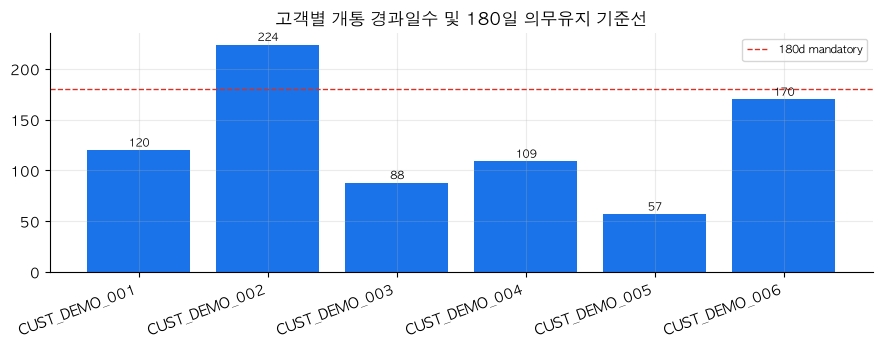

In [5]:
H.show(df_contracts)
H.bar(df_contracts, "customer_id", "elapsed_days", H.t("고객별 개통 경과일수 및 180일 의무유지 기준선", "Elapsed Days per Customer vs. 180-Day Retention Line"), hline=180, hline_label="180d mandatory")


### 3. 단말기 × 요금제별 공시/추가지원금 및 실구매가 히트맵 (`%%bqsql`)


In [6]:
%%bqsql df_sub
SELECT d.device_name, p.plan_name, p.monthly_fee_krw, d.factory_price_krw,
       s.base_subsidy_krw, s.additional_subsidy_cap_krw,
       s.base_subsidy_krw + s.additional_subsidy_cap_krw AS total_subsidy_krw,
       d.factory_price_krw - (s.base_subsidy_krw + s.additional_subsidy_cap_krw) AS net_price_krw
FROM `seanjung-poc.starter_ontology_dw.tb_subsidy_policy` s
JOIN `seanjung-poc.starter_ontology_dw.tb_device_master` d USING (device_id)
JOIN `seanjung-poc.starter_ontology_dw.tb_plan_master` p USING (plan_id)
ORDER BY d.device_name, p.monthly_fee_krw DESC


,device_name,plan_name,monthly_fee_krw,factory_price_krw,base_subsidy_krw,additional_subsidy_cap_krw,total_subsidy_krw,net_price_krw
0,Galaxy S26 Ultra 256GB,5G Premier Super,130000,1698400,500000,75000,575000,1123400
1,Galaxy S26 Ultra 256GB,5G Premier Essential,85000,1698400,450000,67500,517500,1180900
2,Galaxy S26 Ultra 256GB,5G Slim (Baseline Threshold),45000,1698400,300000,45000,345000,1353400
3,Galaxy S26 Ultra 256GB,5G Light (Below Baseline),37000,1698400,150000,22500,172500,1525900
4,iPhone 16 Pro 256GB,5G Premier Essential,85000,1700000,400000,60000,460000,1240000


,device_name,plan_name,monthly_fee_krw,factory_price_krw,base_subsidy_krw,additional_subsidy_cap_krw,total_subsidy_krw,net_price_krw
0,Galaxy S26 Ultra 256GB,5G Premier Super,130000,1698400,500000,75000,575000,1123400
1,Galaxy S26 Ultra 256GB,5G Premier Essential,85000,1698400,450000,67500,517500,1180900
2,Galaxy S26 Ultra 256GB,5G Slim (Baseline Threshold),45000,1698400,300000,45000,345000,1353400
3,Galaxy S26 Ultra 256GB,5G Light (Below Baseline),37000,1698400,150000,22500,172500,1525900
4,iPhone 16 Pro 256GB,5G Premier Essential,85000,1700000,400000,60000,460000,1240000


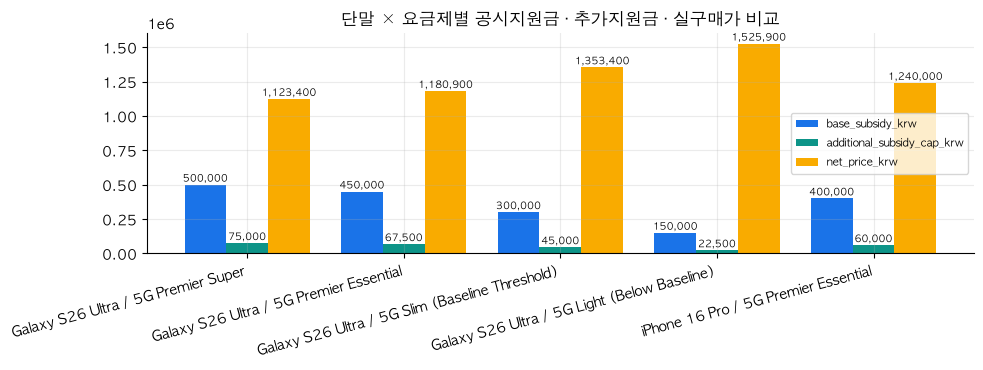

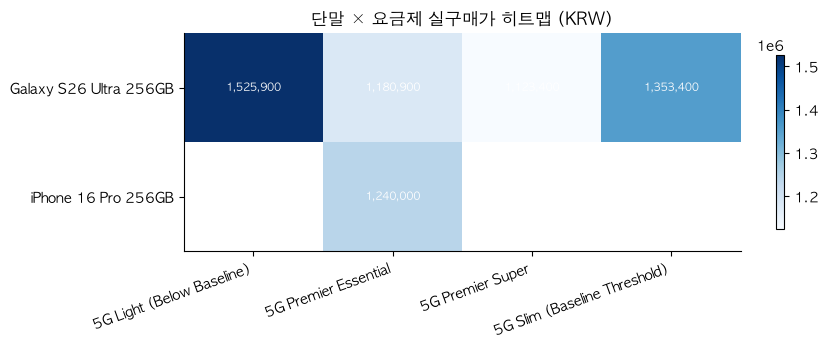

In [7]:
d_sub = H.pdf(df_sub)
d_sub["device_plan"] = d_sub["device_name"].str.replace(" 256GB", "") + " / " + d_sub["plan_name"]
H.show(d_sub[["device_name", "plan_name", "monthly_fee_krw", "factory_price_krw", "base_subsidy_krw", "additional_subsidy_cap_krw", "total_subsidy_krw", "net_price_krw"]])
H.grouped_bar(d_sub, "device_plan", ["base_subsidy_krw", "additional_subsidy_cap_krw", "net_price_krw"], H.t("단말 × 요금제별 공시지원금 · 추가지원금 · 실구매가 비교", "Base Subsidy, Additional Cap & Net Price by Device × Plan"))
H.heatmap(d_sub.pivot(index="device_name", columns="plan_name", values="net_price_krw"), H.t("단말 × 요금제 실구매가 히트맵 (KRW)", "Net Purchase Price Heatmap (KRW)"))


### 4. 비정형 정책 가이드 청크(`DOC_CHUNK_001~005`) 및 도메인 용어 빈도 히트맵 (`%%bqsql`)


In [8]:
%%bqsql df_chunks
SELECT chunk_id, source_file, section_title, trust_tier, CHAR_LENGTH(content) AS chars, content_sha256
FROM `seanjung-poc.starter_ontology_dw.tb_doc_chunks`
ORDER BY chunk_id


,chunk_id,source_file,section_title,trust_tier,chars,content_sha256
0,DOC_CHUNK_001,sample_policy_guide.md,Overview & Scope,GOLDEN_VERIFIED,222,anchor_a52e1a72869f
1,DOC_CHUNK_002,sample_policy_guide.md,Baseline Plan Commitment (Six-Plan Rule),GOLDEN_VERIFIED,467,anchor_3003b683cea0
2,DOC_CHUNK_003,sample_policy_guide.md,Penalty Math Formula,GOLDEN_VERIFIED,444,anchor_47971ec8e4d8
3,DOC_CHUNK_004,sample_welfare_exemption_guide.md,Statutory Penalty Exemptions,GOLDEN_VERIFIED,583,anchor_269d9c42e05c
4,DOC_CHUNK_005,sample_welfare_exemption_guide.md,24-Month Contract TCO Comparison Rule,GOLDEN_VERIFIED,472,anchor_4fbaf9c5cba8


In [9]:
%%bqsql df_terms
SELECT term, chunk_id, ARRAY_LENGTH(REGEXP_EXTRACT_ALL(content, term)) AS hits
FROM `seanjung-poc.starter_ontology_dw.tb_doc_chunks`, UNNEST(['공시지원금', '유통망', '180일', '차액정산', '위약금', '선택약정', '복지']) AS term
ORDER BY term, chunk_id


,term,chunk_id,hits
0,180일,DOC_CHUNK_001,0
1,180일,DOC_CHUNK_002,0
2,180일,DOC_CHUNK_003,0
3,180일,DOC_CHUNK_004,0
4,180일,DOC_CHUNK_005,0
5,공시지원금,DOC_CHUNK_001,0
6,공시지원금,DOC_CHUNK_002,0
7,공시지원금,DOC_CHUNK_003,0
8,공시지원금,DOC_CHUNK_004,0
9,공시지원금,DOC_CHUNK_005,0


,chunk_id,source_file,section_title,trust_tier,chars,content_sha256
0,DOC_CHUNK_001,sample_policy_guide.md,Overview & Scope,GOLDEN_VERIFIED,222,anchor_a52e1a72869f
1,DOC_CHUNK_002,sample_policy_guide.md,Baseline Plan Commitment (Six-Plan Rule),GOLDEN_VERIFIED,467,anchor_3003b683cea0
2,DOC_CHUNK_003,sample_policy_guide.md,Penalty Math Formula,GOLDEN_VERIFIED,444,anchor_47971ec8e4d8
3,DOC_CHUNK_004,sample_welfare_exemption_guide.md,Statutory Penalty Exemptions,GOLDEN_VERIFIED,583,anchor_269d9c42e05c
4,DOC_CHUNK_005,sample_welfare_exemption_guide.md,24-Month Contract TCO Comparison Rule,GOLDEN_VERIFIED,472,anchor_4fbaf9c5cba8


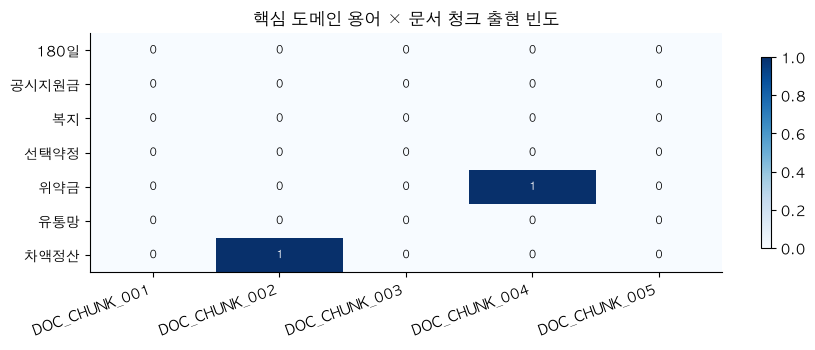

In [10]:
H.show(df_chunks)
H.heatmap(H.pdf(df_terms).pivot(index="term", columns="chunk_id", values="hits"), H.t("핵심 도메인 용어 × 문서 청크 출현 빈도", "Domain Term × Document Chunk Frequency"), fmt="{:.0f}")


### 5. Golden CQ 5종 검증 SQL 대조 및 Boundary 질의 10건 명세


In [11]:
cqs = H.read_json("data/input/04_cq/golden_competency_questions.json")
H.show(H.check_cq_sql(cqs))
bcs = H.read_json("data/input/04_cq/boundary_cases.json")
H.show(bcs, ["case_id", "root_cause_code", "missing_context", "query", "expected_behavior"])


,cq_id,expected_math,bigquery_result,match,job_id
0,CQ-01,{'factory_price': 1698400},{'factory_price': 1698400},True,job_1s3Qg_rgARLbQvjgjAW411-hlH16
1,CQ-02,"{'subsidy': 517500, 'net_price': 1180900}","{'subsidy': 517500, 'net_price': 1180900}",True,job_PjyKoBnvN3kwG9OiHPWF5XjVZ4k6
2,CQ-03,{'penalty': 100000},{'penalty': 100000},True,job__XRTkRDt_kgoo3nzZMDgkluACvWF
3,CQ-04,"{'public_subsidy_total': 517500, 'selective_discount_total': 510000, 'tco_savings': 7500}","{'public_subsidy_total': 517500, 'selective_discount_total': 510000, 'tco_savings': 7500}",True,job_oLunJlo4mfxuj3Tasn-irlKmGM7z
4,CQ-05,"{'penalty': 0, 'exemption_rule': 'RULE_WELFARE_EXEMPT'}","{'penalty': 0, 'exemption_rule': 'RULE_WELFARE_EXEMPT'}",True,job_XziDJOBRNd992HewVxNM6vSzoc1O


,case_id,root_cause_code,missing_context,query,expected_behavior
0,BQ-01,NO_SLOT_FILLING,고객 ID / 현재 요금제 / 변경 희망 요금제 미지정,개통한 지 4개월 됐는데 요금제 낮추면 위약금 나오나요?,금액을 단정하지 않고 부족한 정보(고객 ID·변경 요금제 등)를 안내
1,BQ-02,MISSING_EXCEPTION_EDGE,시니어 특례 면제 등록 여부 미지정,어르신 요금제로 바꾸려는데 180일 안 지났으면 위약금 내야 하나요?,시니어 특례(RULE_WELFARE_EXEMPT / DOC_CHUNK_004) 조건을 안내하고 고객 정보를 요청
2,BQ-03,NO_SLOT_FILLING,용량(256GB/512GB) 및 가입 요금제 미지정,갤럭시 S26 울트라 지금 사면 지원금 얼마 받아요?,BigQuery 지원금 정책의 요금제별 총 지원금을 제시
3,BQ-04,MISSING_ENTITY,군입대 정지 특례 엔티티 참조,군대 입대 때문에 일시정지하면 180일 의무기간은 어떻게 되나요?,군입대 장기정지 특례(MILITARY_PAUSE_ELIGIBLE / DOC_CHUNK_004) 근거를 인용
4,BQ-05,NO_ALIAS_DICT,단말 별칭(아이폰 최신형 프로) 및 요금제 미지정,아이폰 최신형 프로 모델 선약이랑 공시 중 뭐가 더 이득인가요?,카탈로그의 iPhone 16 Pro로 매핑하고 BigQuery 정책 기준 24개월 총비용 차액을 제시
5,BQ-06,NO_SLOT_FILLING,180일 경과 후 면제 경계값,개통 185일째인데 제일 싼 LTE 요금제로 내려도 위약금 없죠?,경과일 185일이 의무기간 이상이므로 위약금 0원
6,BQ-07,MISSING_ENTITY,노드 테이블 중복 키 메타데이터 조회,지원금 테이블이랑 실제 그래프 노드에 중복 적재된 데이터가 있나요?,Stage 3 실측 결과(노드 테이블 중복 키 건수)를 제시
7,BQ-08,MISSING_EXCEPTION_EDGE,기준선 이상 요금제 간 하향 시 차액정산 여부,5G 프리미어 에센셜에서 다이렉트 61로 바꾸면 기준선 위반인가요?,변경 요금제 월정액이 기준선 이상이므로 기준선 위반 아님
8,BQ-09,MISSING_ENTITY,법인(Corporate_B2B) 세그먼트 정책 매핑,법인 명의로 개통한 회선도 180일 식스플랜 룰이 똑같이 적용되나요?,세그먼트별 예외 규칙 존재 여부를 도구 결과로 밝히고 RULE_SIX_PLAN_180D 근거를 인용
9,BQ-10,NO_ALIAS_DICT,BigQuery Graph vs Spanner Graph 호환성,Spanner Graph로 전환하면 지금 쓰는 GQL 쿼리랑 스키마를 다 새로 짜야 하나요?,도구 실측 결과(BigQuery Property Graph)에 근거해 답하고 결과에 없는 내용은 단정하지 않음
